# Análisis del primer mes de soporte técnico en SAASCANET

**SAASCANET** es la intranet que desarrollé para el SAASCAEM, un organismo público del Estado de México con ~110 usuarios. Uno de sus módulos registra cada solicitud de soporte técnico: quién la pidió, de qué área, qué problema era, quién la atendió y cuánto tardó.

Este análisis usa los tickets del **primer mes de operación de la versión actualizada** (29 de septiembre al 29 de octubre de 2026).

**Preguntas de negocio**
1. ¿Qué áreas piden más soporte y por qué tipo de problemas?
2. ¿Qué tan rápido se resuelven las solicitudes?
3. ¿Las categorías del formulario describen bien los problemas reales?
4. ¿Hay problemas recurrentes que convenga atender de raíz?
5. ¿Cuándo se concentra la demanda?

> **Sobre los datos:** se eliminaron nombres, comentarios y notas (texto libre con datos personales). Los usuarios y técnicos se reemplazaron por seudónimos (`Usuario 01`, `Técnico A`). El tema de cada ticket se clasificó a partir del texto libre antes de eliminarlo (ver `scripts/anonimizar.py`).

In [1]:
import sqlite3, re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 60)

# Cargamos el CSV anonimizado
tickets = pd.read_csv('../data/tickets_anonimizados.csv', parse_dates=['registrado', 'resuelto'])
print(tickets.shape)
tickets.head()

(74, 11)


,folio,usuario,area,equipo_tipo,tipo_formulario,tema,estatus,registrado,resuelto,tecnico,n_participantes
0,GTR-0096,Usuario 04,Dirección de Operación,Laptop,Solicitud de soporte,Fuentes tipográficas,Resuelto,2026-10-29 11:15:56,2026-10-29 11:43:47,Técnico B,1
1,GTR-0095,Usuario 24,Dirección de Operación,PC de escritorio,Sistemas de gestión y correos,Fuentes tipográficas,Resuelto,2026-10-29 10:51:24,2026-10-29 11:36:16,Técnico A,1
2,GTR-0094,Usuario 24,Dirección de Operación,PC de escritorio,Sistemas de gestión y correos,"Accesos, correo y sistemas",Resuelto,2026-10-29 10:49:28,2026-10-29 11:37:09,Técnico C,1
3,GTR-0093,Usuario 29,Dirección de Proyectos y Control de Obras,Laptop,Solicitud de soporte,"Accesos, correo y sistemas",Resuelto,2026-10-29 10:31:27,2026-10-29 10:31:54,Técnico C,1
4,GTR-0092,Usuario 24,Dirección de Operación,PC de escritorio,Falla técnica,Rendimiento y hardware,Resuelto,2026-10-28 17:27:54,2026-10-28 17:37:21,Técnico C,2


### ¿Por qué SQL?
En la intranet los datos viven en MySQL, así que las preguntas se responden con **consultas SQL** (archivo `sql/consultas.sql`). Para que el notebook funcione en cualquier computadora sin instalar un servidor, cargo el CSV en una base **SQLite en memoria** y ejecuto ahí las mismas consultas. Python se usa solo para las gráficas y para la mediana, que SQLite no calcula de forma nativa.

In [2]:
# Base SQLite en memoria con la tabla 'tickets'
con = sqlite3.connect(':memory:')
pd.read_csv('../data/tickets_anonimizados.csv').to_sql('tickets', con, index=False)

# Leemos el archivo de consultas: cada una empieza con '-- name: <nombre>'
sql = open('../sql/consultas.sql', encoding='utf-8').read()
consultas = dict(re.findall(r'-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)', sql, re.S))

def q(nombre):
    """Ejecuta la consulta con ese nombre y regresa un DataFrame."""
    return pd.read_sql(consultas[nombre], con)

print(list(consultas))

['resumen_general', 'tickets_por_area', 'tickets_por_tema', 'tema_principal_por_area', 'categoria_otro_formulario', 'problemas_recurrentes', 'tickets_por_hora', 'tickets_por_dia', 'calidad_fechas', 'folios_faltantes']


In [3]:
# Estilo de las gráficas: un solo color, texto gris oscuro y sin bordes innecesarios
AZUL, TEXTO, TEXTO2, GRID = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRID,
                     'axes.labelcolor': TEXTO2, 'xtick.color': TEXTO2, 'ytick.color': TEXTO2,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
                     'figure.facecolor': 'white'})

def barras_h(df, col_cat, col_val, titulo, archivo, etiqueta=''):
    df = df.sort_values(col_val)
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(df) + 1.2))
    ax.barh(df[col_cat], df[col_val], color=AZUL, height=0.65)
    for y, v in enumerate(df[col_val]):
        ax.text(v, y, f' {v:g}{etiqueta}', va='center', color=TEXTO, fontsize=9)
    ax.set_title(titulo, color=TEXTO)
    ax.xaxis.set_visible(False); ax.spines['bottom'].set_visible(False)
    fig.tight_layout(); fig.savefig(f'../images/{archivo}', dpi=130); plt.show()

## 1. Calidad de los datos
Antes de analizar, reviso que los datos sean confiables. Es el primer mes del sistema, así que también sirve para detectar qué mejorar en la captura.

In [4]:
# Tickets cuya fecha de resolución es ANTERIOR a la de registro (imposible en la realidad)
q('calidad_fechas')

,folio,registrado,resuelto,minutos
0,GTR-0053,2026-10-13 13:26:40,2026-10-13 12:48:21,-38.3
1,GTR-0052,2026-10-13 13:22:12,2026-10-13 13:18:48,-3.4


In [5]:
# Huecos en la secuencia de folios: tickets que se eliminaron o no se guardaron
q('folios_faltantes')

,folio_faltante
0,GTR-0042
1,GTR-0045
2,GTR-0054
3,GTR-0062


**Hallazgos de calidad:**
- **2 tickets** tienen la fecha de resolución antes que la de registro. Probablemente se capturaron después de resolverse. Los excluyo de los cálculos de tiempo.
- Faltan **4 folios** en la secuencia (GTR-0042, 0045, 0054 y 0062). Conviene revisar si se borraron y dejar registro en la bitácora.
- El campo *Equipo* es texto libre: en el CSV original había **más de 25 formas distintas** de escribir lo mismo ("laptop", "lap top", "LAP-TOP"...). Lo normalicé en 4 categorías, y la recomendación es convertirlo en una lista desplegable.

In [6]:
# Tiempo de resolución en minutos, solo para tickets resueltos con fechas válidas
tickets['minutos'] = (tickets['resuelto'] - tickets['registrado']).dt.total_seconds() / 60
validos = tickets[(tickets['estatus'] == 'Resuelto') & (tickets['minutos'] >= 0)].copy()
print(f'Tickets totales: {len(tickets)} | resueltos con fechas válidas: {len(validos)}')

Tickets totales: 74 | resueltos con fechas válidas: 69


## 2. Panorama general

In [7]:
q('resumen_general')

,total_tickets,resueltos,no_procede,primer_dia,ultimo_dia,pct_resuelto_en_1h,pct_mismo_dia
0,74,71,3,2026-09-29,2026-10-29,63.8,86.5


In [8]:
# La mediana es más representativa que el promedio: unos pocos tickets tardan días y lo inflan
print(f"Mediana de resolución: {validos['minutos'].median():.0f} minutos")
print(f"Promedio de resolución: {validos['minutos'].mean():.0f} minutos")

Mediana de resolución: 26 minutos
Promedio de resolución: 311 minutos


En un mes llegaron **74 solicitudes**, unas 3 por día hábil. La **mitad se resolvió en menos de media hora**, el 64% en menos de una hora y el 86% el mismo día. El promedio (~5 horas) engaña porque unos pocos casos tardaron días; por eso uso la **mediana**.

## 3. ¿Qué áreas piden más soporte?

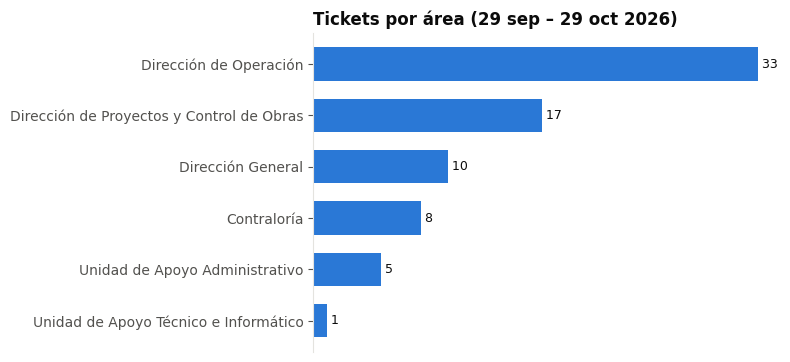

,area,tickets,pct_del_total,usuarios_distintos
0,Dirección de Operación,33,44.6,13
1,Dirección de Proyectos y Control de Obras,17,23.0,7
2,Dirección General,10,13.5,3
3,Contraloría,8,10.8,4
4,Unidad de Apoyo Administrativo,5,6.8,2
5,Unidad de Apoyo Técnico e Informático,1,1.4,1


In [9]:
por_area = q('tickets_por_area')
barras_h(por_area, 'area', 'tickets', 'Tickets por área (29 sep – 29 oct 2026)', 'tickets_por_area.png')
por_area

In [10]:
# Tema principal de cada área (consulta con la función de ventana ROW_NUMBER)
q('tema_principal_por_area')

,area,tema_principal,tickets
0,Dirección de Operación,Grabación y copia de CD,6
1,Dirección de Proyectos y Control de Obras,Puertos USB,5
2,Contraloría,Software y licencias,4
3,Dirección General,"Accesos, correo y sistemas",2
4,Unidad de Apoyo Administrativo,Impresión y escaneo,2
5,Unidad de Apoyo Técnico e Informático,Rendimiento y hardware,1


La **Dirección de Operación** concentra casi la mitad de los tickets (45%), seguida de Proyectos y Control de Obras (23%). Cada área tiene un problema distinto: en Operación predomina la copia de información entre CD y USB, y en Proyectos las fallas de puertos USB.

## 4. ¿Qué problemas llegan y cuánto tardan?

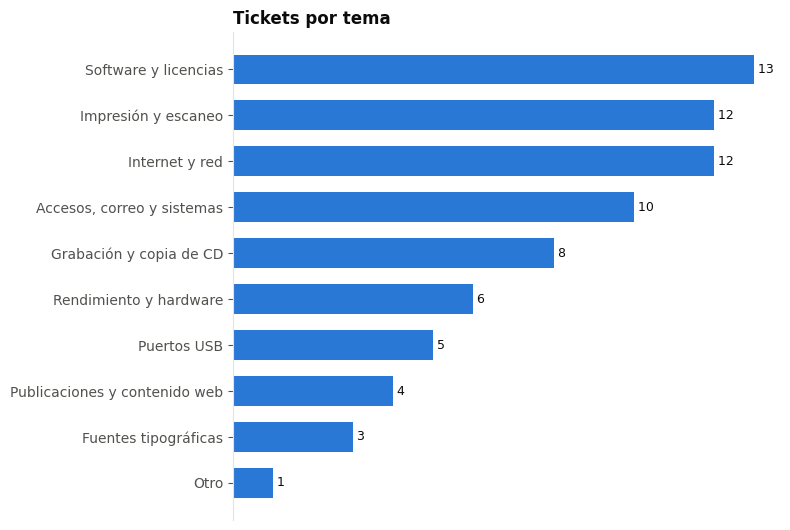

,tema,tickets,minutos_promedio,pct_en_1h,mediana_minutos
0,Software y licencias,13,230.0,58.0,34.0
1,Internet y red,12,427.0,50.0,67.0
2,Impresión y escaneo,12,392.0,73.0,20.0
3,"Accesos, correo y sistemas",10,779.0,63.0,37.0
4,Grabación y copia de CD,8,48.0,86.0,6.0
5,Rendimiento y hardware,6,329.0,50.0,64.0
6,Puertos USB,5,98.0,40.0,115.0
7,Publicaciones y contenido web,4,35.0,75.0,13.0
8,Fuentes tipográficas,3,28.0,100.0,28.0
9,Otro,1,20.0,100.0,20.0


In [11]:
por_tema = q('tickets_por_tema')
mediana = validos.groupby('tema')['minutos'].median().round(0).rename('mediana_minutos')
por_tema = por_tema.merge(mediana, left_on='tema', right_index=True)
barras_h(por_tema, 'tema', 'tickets', 'Tickets por tema', 'tickets_por_tema.png')
por_tema

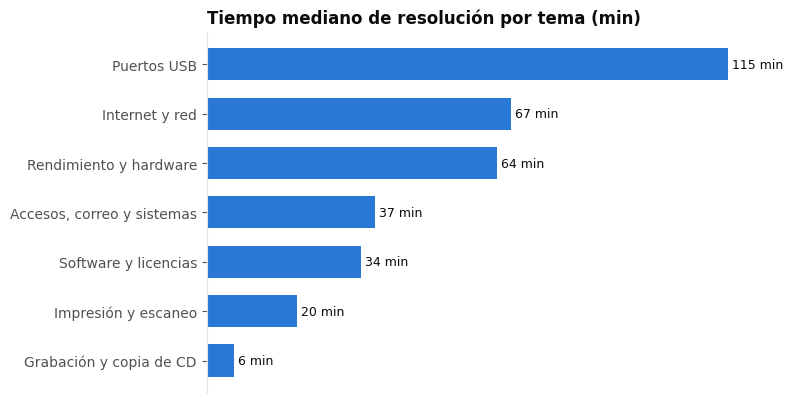

In [12]:
temas_5 = por_tema[por_tema['tickets'] >= 5]          # solo temas con suficientes casos
barras_h(temas_5, 'tema', 'mediana_minutos', 'Tiempo mediano de resolución por tema (min)',
         'tiempo_por_tema.png', ' min')

Software y licencias, internet e impresión suman casi la mitad de las solicitudes. Los **puertos USB** son lo que más tarda (mediana de ~2 horas), porque requieren revisar el equipo físicamente. Las tareas de copia a CD y de impresión se resuelven en minutos, pero ocupan tiempo del equipo técnico.

## 5. ¿El formulario describe bien los problemas?

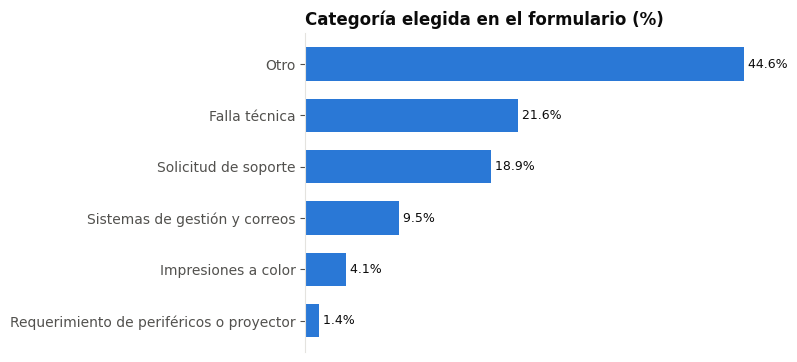

,tipo_formulario,tickets,pct_del_total
0,Otro,33,44.6
1,Falla técnica,16,21.6
2,Solicitud de soporte,14,18.9
3,Sistemas de gestión y correos,7,9.5
4,Impresiones a color,3,4.1
5,Requerimiento de periféricos o proyector,1,1.4


In [13]:
formulario = q('categoria_otro_formulario')
barras_h(formulario, 'tipo_formulario', 'pct_del_total', 'Categoría elegida en el formulario (%)',
         'categorias_formulario.png', '%')
formulario

In [14]:
# ¿Qué problemas reales quedaron escondidos en la categoría 'Otro'?
tickets[tickets['tipo_formulario'] == 'Otro']['tema'].value_counts()

tema
Software y licencias             8
Grabación y copia de CD          8
Publicaciones y contenido web    4
Impresión y escaneo              3
Puertos USB                      3
Internet y red                   3
Accesos, correo y sistemas       2
Fuentes tipográficas             1
Rendimiento y hardware           1
Name: count, dtype: int64

**El 45% de los tickets se registró como "Otro".** Las categorías actuales del formulario no describen lo que realmente piden los usuarios. Dentro de "Otro" hay problemas muy concretos: copia de CD, impresión, software o puertos USB. **Recomendación:** cambiar las categorías del formulario por los temas que aparecen en los datos. Así el reporte sale directo del sistema, sin clasificar a mano.

## 6. Problemas recurrentes

In [15]:
q('problemas_recurrentes')

,usuario,area,tema,veces,primera_vez,ultima_vez
0,Usuario 14,Dirección de Proyectos y Control de Obras,Puertos USB,5,2026-10-08,2026-10-28
1,Usuario 11,Contraloría,Software y licencias,3,2026-10-15,2026-10-28
2,Usuario 12,Dirección de Operación,Internet y red,3,2026-09-29,2026-10-06


Un mismo usuario reportó **5 veces** fallas en puertos USB en tres semanas. Eso no es un problema de configuración, sino una falla de fondo del equipo. En las notas técnicas ya se recomendaba cambiar el disco duro. **Recomendación:** cuando un usuario repite el mismo tema 3 veces, escalarlo a reemplazo o mantenimiento mayor en lugar de volver a atenderlo.

## 7. ¿Cuándo se concentra la demanda?

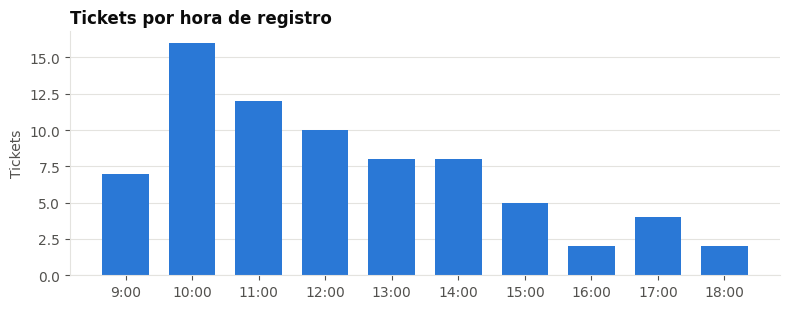

In [16]:
por_hora = q('tickets_por_hora')
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(por_hora['hora'], por_hora['tickets'], color=AZUL, width=0.7)
ax.set_xticks(por_hora['hora']); ax.set_xticklabels([f'{h}:00' for h in por_hora['hora']])
ax.set_title('Tickets por hora de registro', color=TEXTO); ax.set_ylabel('Tickets')
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig('../images/tickets_por_hora.png', dpi=130); plt.show()

In [17]:
q('tickets_por_dia')

,dia,tickets
0,1 Lunes,10
1,2 Martes,13
2,3 Miércoles,17
3,4 Jueves,21
4,5 Viernes,13


El **38% de las solicitudes llega entre las 10:00 y las 12:00**, y el jueves es el día con más tickets. Es buen momento para tener a todo el equipo disponible y dejar el mantenimiento preventivo para la tarde.

## Conclusiones y recomendaciones

| Hallazgo | Recomendación |
|---|---|
| 45% de los tickets se registra como "Otro" | Rediseñar las categorías del formulario con los temas reales |
| 5 tickets de USB del mismo usuario en 3 semanas | Escalar a reemplazo cuando un problema se repite 3 veces |
| 8 tickets de copia entre CD y USB (11%) | Crear una guía o un equipo de autoservicio para esa tarea |
| 3 instalaciones de la fuente Gotham | Incluirla en la configuración estándar de los equipos |
| El campo *Equipo* tiene más de 25 formas de escribirse | Cambiarlo por una lista desplegable o el número de inventario |
| 2 tickets con fechas inconsistentes y 4 folios faltantes | Validar fechas al guardar y registrar eliminaciones en la bitácora |

## Limitaciones
- **Es un mes de datos (74 tickets).** Los patrones son iniciales y hay que confirmarlos con más meses.
- El tema se infirió del texto libre con reglas de palabras clave, así que puede haber errores de clasificación.
- Los tiempos incluyen horas fuera de jornada cuando un ticket se cierra al día siguiente.
- No comparo el desempeño de los técnicos: con 3 personas, el dato sería identificable aunque esté anonimizado.